## Hebb's Rule:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

class HebbianNeuron :
    """ Neuron with Hebbian learning rule """
    def __init__ ( self , n_inputs , learning_rate =0.01) :
        """
        Initialize Hebbian neuron
        Parameters :
        n_inputs : number of inputs
        learning_rate : eta ( learning rate )
        """
        self.lr = learning_rate
    # Small random initialization
        self.weights = np.random.randn( n_inputs ) * 0.1
        self.bias = np.random.randn() * 0.1
        self.weight_history = [] # For visualization

    def activation ( self , x ) :
        """ Sigmoid activation function """
        z = np.dot (x , self.weights ) + self.bias
        return 1 / (1 + np.exp( - z ) )

    def predict ( self , x ) :
        """ Binary prediction ( for after learning ) """
        return 1 if self.activation( x ) > 0.5 else 0

    def hebbian_update ( self , x , y ) :
        """
        Hebb's rule : delta w = eta * x * y

        Note : y is the neuron's output , not the target !
        """
        self.weights += self.lr * x * y
        self.bias += self.lr * y # Bias sees constant input = 1

    def train ( self , X , epochs =10 , verbose = True ) :
        """
        Unsupervised Hebbian learning
        Parameters :
        X : input data
        epochs : number of passes through the data
        verbose : print progress
        """
        self.weight_history = []

        for epoch in range ( epochs ) :
            for x in X :
                y = self.activation( x )
                self.hebbian_update(x , y )

        # Save for visualization
            self.weight_history.append( self.weights.copy() )

            if verbose and ( epoch + 1) % 5 == 0:
                print ( f"Epoch {epoch+1}/{epochs}, Weights:{self.weights}")

        return self

## Learning Simple Patterns

Epoch 5/30, Weights:[0.16687941 0.44886645]
Epoch 10/30, Weights:[0.19897499 0.64301834]
Epoch 15/30, Weights:[0.23068619 0.83679329]
Epoch 20/30, Weights:[0.26239736 1.03056823]
Epoch 25/30, Weights:[0.29410853 1.22434316]
Epoch 30/30, Weights:[0.32581971 1.4181181 ]


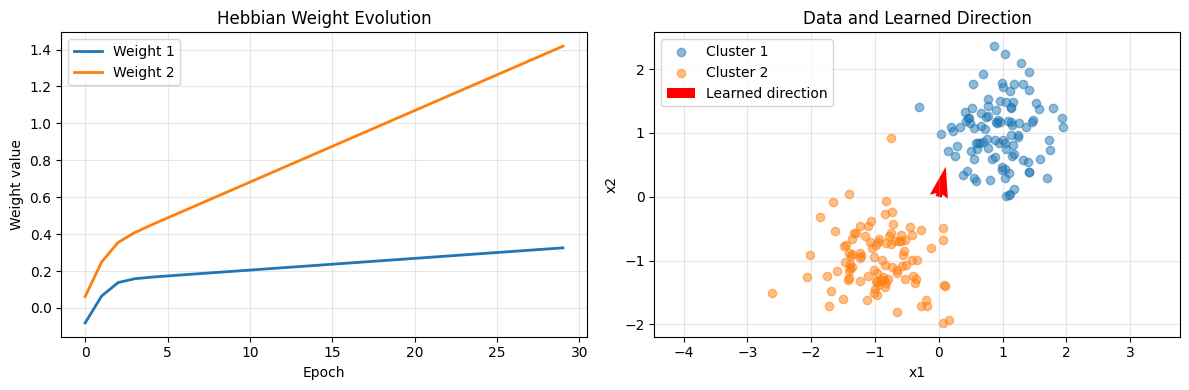


Final weights: [0.32581971 1.4181181 ]
The neuron has learned to point in the direction of maximum correlation


In [2]:
# Create a simple dataset with structure
np.random.seed(42)

#Create two clusters of points
n_samples = 100
cluster1 = np.random.randn(n_samples, 2) *0.5 + np.array([1,1]) #Around (1,1)

cluster2= np.random.randn(n_samples ,2)* 0.5 + np.array([-1,-1]) # Around (-1,-1)
X = np.vstack([cluster1, cluster2])
#Train Hebbian neuron
hebb = HebbianNeuron(n_inputs = 2, learning_rate = 0.01)
hebb.train(X, epochs = 30, verbose = True)
#Visualize the learning process
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
weight_history=np.array(hebb.weight_history)
plt.plot(weight_history[:,0], label='Weight 1', linewidth = 2)
plt.plot(weight_history[:,1], label='Weight 2', linewidth = 2)
plt.xlabel('Epoch')
plt.ylabel('Weight value')
plt.title('Hebbian Weight Evolution')
plt.legend()
plt.grid(True, alpha=0.3)
plt.subplot(1,2,2)
plt.scatter(X[:n_samples,0], X[:n_samples ,1], alpha =0.5, label='Cluster 1')
plt.scatter(X[n_samples:,0],X[n_samples:, 1], alpha = 0.5, label='Cluster 2')

#plot final weight direction
origin = np.array([0,0])
plt.quiver(*origin, hebb.weights[0], hebb.weights[1], angles = 'xy', scale_units = 'xy', scale = 3, color ='red', label='Learned direction', width=0.02)

plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Data and Learned Direction')
plt.legend()
plt.grid(True, alpha =0.3)
plt.axis('equal')
plt.tight_layout()
plt.show()

print(f"\nFinal weights: {hebb.weights}")
print(f"The neuron has learned to point in the direction of maximum correlation")

## Learning Logic Gates with Hebbian Rule 

In [3]:
# Data for logic gates 
X_logic = np.array([[0,0], [0,1], [1,0],[1,1]])
#For Hebbian learning, we don't provide targets!
#The neuron will learni based on correlations in the data
def train_hebbian_on_gate(X,gate_name, learning_rate = 0.1, epochs = 100):
    #Train a Hebbian neuron on logic gate inputs and analyze results
    hebb = HebbianNeuron(n_inputs =2, learning_rate = learning_rate)
    print(f"\nTraining Hebbian neuron on {gate_name} gate inputs")
    print("-" * 50)
    print("Initial weights:", hebb.weights)
    #Train on the inputs (no targets!)
    hebb.train(X, epochs=epochs, verbose = False)
    print("Final weights:", hebb.weights)
    #test the neuron's reponses to each input
    print("\nNeuron responses")
    print("A B | Activation | Prediction")
    print("----+------------+-----------")
    for inputs in X:
        act = hebb.activation(inputs)
        pred = hebb.predict(inputs)
        print(f"{inputs[0]} {inputs[1]} | {act:.4f} | {pred}")
    return hebb
#Train on AND gate inputs 
hebb_and  = train_hebbian_on_gate(X_logic, "AND")
#Train on OR gate inputs
hebb_or = train_hebbian_on_gate(X_logic, "OR")
#Train on XOR gate inputs
hebb_xor = train_hebbian_on_gate(X_logic, "XOR")



Training Hebbian neuron on AND gate inputs
--------------------------------------------------
Initial weights: [ 0.00469806 -0.04500655]
Final weights: [19.71558306 19.65078762]

Neuron responses
A B | Activation | Prediction
----+------------+-----------
0 0 | 1.0000 | 1
0 1 | 1.0000 | 1
1 0 | 1.0000 | 1
1 1 | 1.0000 | 1

Training Hebbian neuron on OR gate inputs
--------------------------------------------------
Initial weights: [-0.10676204 -0.01423795]
Final weights: [19.56295738 19.65851407]

Neuron responses
A B | Activation | Prediction
----+------------+-----------
0 0 | 1.0000 | 1
0 1 | 1.0000 | 1
1 0 | 1.0000 | 1
1 1 | 1.0000 | 1

Training Hebbian neuron on XOR gate inputs
--------------------------------------------------
Initial weights: [0.05144388 0.07116149]
Final weights: [19.73703918 19.75009168]

Neuron responses
A B | Activation | Prediction
----+------------+-----------
0 0 | 1.0000 | 1
0 1 | 1.0000 | 1
1 0 | 1.0000 | 1
1 1 | 1.0000 | 1


## Effect of Learning Rate on Hebbian Learning

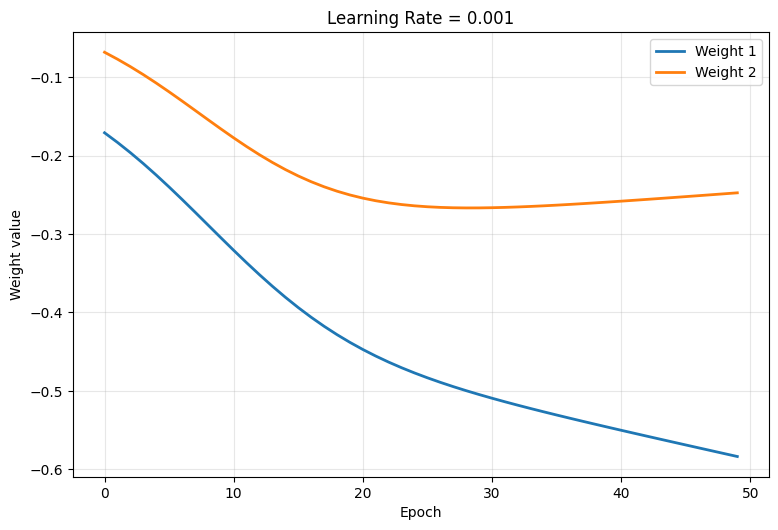


Learning Rate Comparison:
--------------------------------------------------


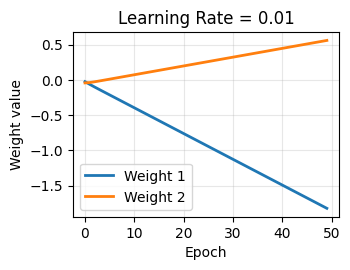


Learning Rate Comparison:
--------------------------------------------------


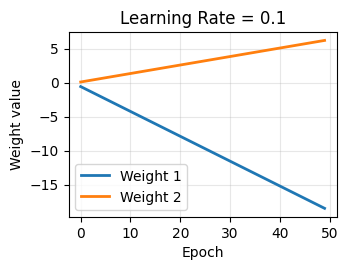


Learning Rate Comparison:
--------------------------------------------------


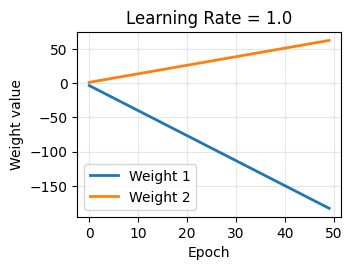


Learning Rate Comparison:
--------------------------------------------------
LR = 0.001 : Final weights = [-0.58397887 -0.24746876],Norm = 0.6342
LR = 0.01 : Final weights = [-1.8227426  0.5579585],Norm = 1.9062
LR = 0.1 : Final weights = [-18.48798451   6.20998746],Norm = 19.5031
LR = 1.0 : Final weights = [-182.67350208   62.24983827],Norm = 192.9887


In [19]:
def compare_hebbian_learning_rates(X, learning_rates = [0.001, 0.01, 0.1, 1.0], epochs=50):
    #Compare Hebbian learning with different learning rates
    
    plt.figure(figsize = (15,10))
    results = {}
    for i ,lr in enumerate(learning_rates):
        
        #Train neuron
        hebb = HebbianNeuron(n_inputs = X.shape[1], learning_rate = lr)
        hebb.train(X, epochs=epochs, verbose = False)
        # Plot weight evolution
        plt.subplot(2,2,i+1)
        weight_history = np.array(hebb.weight_history)
        plt.plot(weight_history[:,0], label='Weight 1', linewidth=2)
        plt.plot(weight_history[:,1], label='Weight 2', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Weight value')
        plt.title(f'Learning Rate = {lr}')
        plt.legend()
        plt.grid(True, alpha=0.3)
        #Store results
        results[lr] = {
        'final_weights': hebb.weights.copy(),
        'weight_norm': np.linalg.norm(hebb.weights)
        }
        plt.tight_layout()
        plt.show()
        #Print comparison
        print("\nLearning Rate Comparison:")
        print("-" * 50)
    for lr, res in results.items():
        print(f"LR = {lr} : Final weights = {res['final_weights']},"f"Norm = {res['weight_norm']:.4f}")
    return results
        
#Generate coorelated data
np.random.seed(42)
X_corr = np.random.multivariate_normal(
    mean=[0,0],
    cov=[[1,0.8],[0.8,1]],
    size=200
)
results = compare_hebbian_learning_rates(X=X_corr)

## Problem of Weight Divergence

Training with constant inputs [1,1] - weights will diverge!


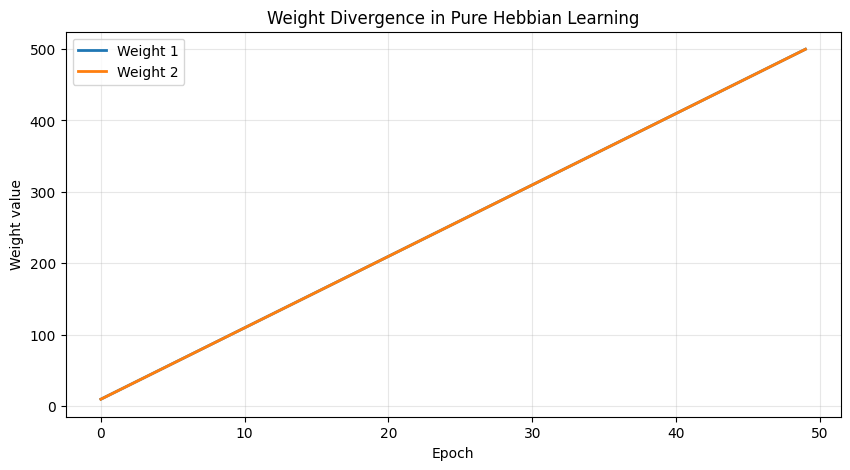

Final weights after 50 epochs: [499.64419325 499.59448865]
Weights keep growing indefinitely - this is unstable!


In [5]:
#Demonstrate weight divergence
hebb_divergent = HebbianNeuron(n_inputs  = 2, learning_rate = 0.1)
#Create data where all inputs are [1,1]
X_ones = np.ones((100,2))
print("Training with constant inputs [1,1] - weights will diverge!")
hebb_divergent.train(X_ones, epochs=50, verbose= False)
plt.figure(figsize=(10,5))
weight_history = np.array(hebb_divergent.weight_history)
plt.plot(weight_history[:,0], label='Weight 1', linewidth=2)
plt.plot(weight_history[:,1], label='Weight 2', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Weight value')
plt.title('Weight Divergence in Pure Hebbian Learning')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
print(f"Final weights after 50 epochs: {hebb_divergent.weights}")
print("Weights keep growing indefinitely - this is unstable!")

## Oja's Rule: A Normalized Solution


Comparing Hebbs vs Oja constant inputs


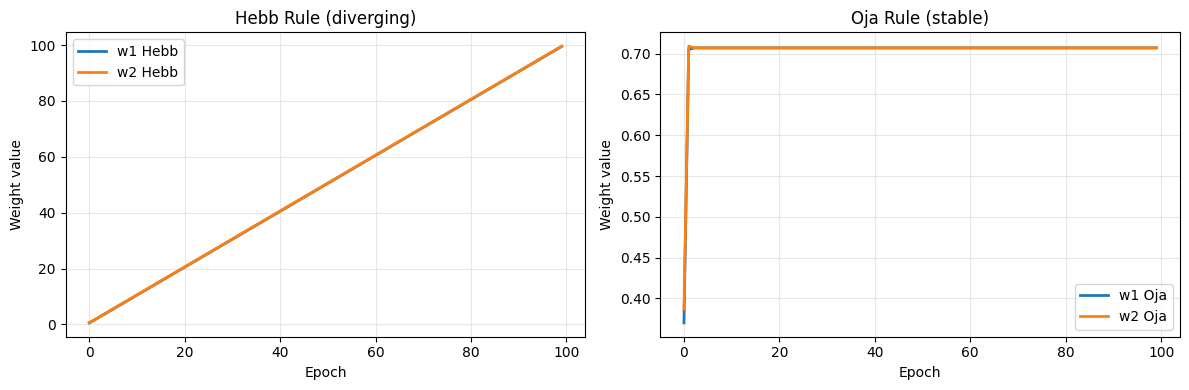

Hebb final weights: [99.51777984 99.61030394]
Oja final weights: [0.70710678 0.70710678]
Oja final weight norm: 1.0000


In [6]:
class OjaNeuron: 
    """
    Oja's rule: delta w = eta (x u - y^2 w)
    This prevents weight divergence by adding a normalization term
    """
    def __init__(self,n_inputs, learning_rate=0.01):
        self.lr= learning_rate
        self.weights = np.random.randn(n_inputs) * 0.1
        self.bias = 0 #Oja's rule typically doesn't use bias
        self.weight_history = []
    def activation(self,x):
        return np.dot(x,self.weights)
    def oja_update(self,x):
        #Oja's update rule
        y=self.activation(x)
        self.weights +=self.lr * (y * x - y**2 * self.weights)
    def train(self,X,epochs=50, verbose=True):
        self.weight_hisotry=[]
        for epoch in range(epochs):
            for x in X:
                self.oja_update(x)
            self.weight_history.append(self.weights.copy())

            #Optional: normalize to unit length for stability
            norm = np.linalg.norm(self.weights)
            if norm> 0:
                self.weights = self.weights / norm
            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch +1}/{epochs}, Weight : {self.weight}, Norm: {norm:.4f}")
        return self
#Comapre Hebb vs Oja on constant inputs
print("\n" + "="*60)
print("Comparing Hebbs vs Oja constant inputs")
print("="*60)
X_ones = np.ones((100,2))
hebb_test = HebbianNeuron(2,learning_rate = 0.01)
oja_test = OjaNeuron(2,learning_rate = 0.01)
hebb_test.train(X_ones, epochs = 100, verbose = False)
oja_test.train(X_ones, epochs = 100, verbose = False)

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
hebb_history = np.array(hebb_test.weight_history)
plt.plot(hebb_history[:,0], label='w1 Hebb', linewidth=2)
plt.plot(hebb_history[:,1], label='w2 Hebb', linewidth=2)
plt.title('Hebb Rule (diverging)')
plt.legend()
plt.grid(True,alpha=0.3)
plt.xlabel('Epoch')
plt.ylabel('Weight value')

plt.subplot(1,2,2)
oja_history = np.array(oja_test.weight_history)
plt.plot(oja_history[:,0], label='w1 Oja', linewidth=2)
plt.plot(oja_history[:,1], label='w2 Oja', linewidth=2)
plt.title('Oja Rule (stable)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlabel('Epoch')
plt.ylabel('Weight value')
plt.tight_layout()
plt.show()

print(f"Hebb final weights: {hebb_test.weights}")
print(f"Oja final weights: {oja_test.weights}")
print(f"Oja final weight norm: {np.linalg.norm(oja_test.weights):.4f}")

## Hebbian Learning as Principal Component Analysis

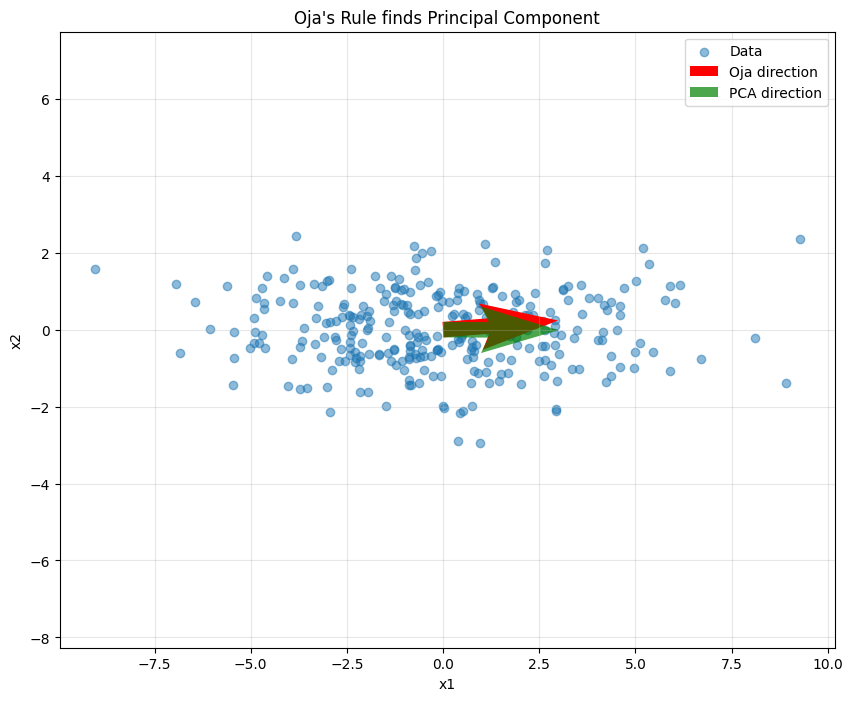

Oja direction: [0.99684196 0.07941101]
PCA direction: [ 0.99998859 -0.00477795]
Dot product (should be near 1): 0.9965


In [7]:
#Generate data with a clear principal component
np.random.seed(42)
n_points = 300

#Create elongated cluster (strong principal component)
angle = np.pi / 4 # 45 degrees 
rotation = np.array([[np.cos(angle), -np.sin(angle)],[np.sin(angle),np.cos(angle)]])
X_elongated = np.random.randn(n_points, 2) @ rotation
X_elongated[:,0] *= 3 #Stretch in first direction

#Train Oja neuron
oja_pca = OjaNeuron(2, learning_rate = 0.01)
oja_pca.train(X_elongated, epochs= 100, verbose = False)

#Visualize
plt.figure(figsize=(10,8))
plt.scatter(X_elongated[:,0], X_elongated[:,1], alpha=0.5, label='Data')

#Plot Oja's learned direction
origin= np.array([0,0])
scale = 3
plt.quiver(*origin, oja_pca.weights[0] * scale, oja_pca.weights[1] * scale,
           angles='xy', scale_units='xy', scale = 1,
           color='red', label='Oja direction', width = 0.02)

#Plot actual principal component (for comparison)
from sklearn.decomposition import PCA
pca = PCA(n_components = 1)
pca.fit(X_elongated)
pca_direction = pca.components_[0]
plt.quiver(*origin, pca_direction[0] * scale, pca_direction[1] * scale,
           angles ='xy', scale_units ='xy', scale =1,
           color ='green', label='PCA direction', width = 0.02,
           alpha = 0.7)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title("Oja's Rule finds Principal Component")
plt.legend()
plt.grid(True, alpha=0.3)
plt.axis('equal')
plt.show()

print(f"Oja direction: {oja_pca.weights}")
print(f"PCA direction: {pca_direction}")
print(f"Dot product (should be near 1): {np.abs(np.dot(oja_pca.weights, pca_direction)):.4f}")




## Simple Associative Memory with Hebbian Learning 

In [8]:
2
class AssociativeMemory:
    """ Simple associative memory using Hebbian learning """

    def __init__( self , pattern_size , learning_rate =0.1) :
        self.pattern_size = pattern_size
        self.lr = learning_rate
        # Initialize weights matrix ( associative memory )
        self.weights = np.zeros(( pattern_size , pattern_size ) )
    def memorize( self , pattern ) :
        """
        Memorize a pattern using Hebbian learning
        Parameters :
        pattern : array of -1/1 values
        """
        pattern = np.array( pattern )
        # Hebbian update : outer product
        self.weights += self.lr * np.outer( pattern , pattern )
        # Zero diagonal ( no self - connection )
        np.fill_diagonal( self.weights , 0)

    def recall( self , partial_pattern , steps =5) :
        """
        Recall a pattern from partial input
        Parameters :
        partial_pattern : array with -1/1 and possibly 0 for
        unknown
        steps : number of update steps
        
        Returns :
        array : recalled pattern
        """
        state = np.array( partial_pattern ).copy()
        for _ in range( steps ) :
            for i in range( self.pattern_size ) :
                if partial_pattern[ i ] == 0: # Only update unknown bits
                    
                    # Compute net input
                    net_input = np.dot( self.weights[ i ] , state )
                    state[ i ] = 1 if net_input > 0 else -1
            
        return state

    def print_pattern( self , pattern , title = " Pattern " ) :
        """ Print pattern as string for visualization ( using ASCII
        ) """
        print( f" { title }: " , end = " " )
        for p in pattern :
            if p == 1:
                print('1' , end ='')
            elif p == -1:
                print('0' , end ='')
            else :
                print('?' , end ='')
        print()
# Example : memorize and recall patterns
memory = AssociativeMemory( pattern_size =8)

# Create some patterns
pattern1 = np.array([1 , 1 , 1 , -1 , -1 , -1 , 1 , 1])
pattern2 = np.array([1 , -1 , 1 , -1 , 1 , -1 , 1 , -1])
print( " = " *60)
print( " ASSOCIATIVE MEMORY WITH HEBBIAN LEARNING " )
print( " = " *60)

memory.print_pattern( pattern1 , " Pattern 1 " )
memory.print_pattern( pattern2 , " Pattern 2 " )
# Memorize patterns
memory.memorize( pattern1 )
memory.memorize( pattern2 )

print( " \ n " + " -" *40)
print( " Recall Tests " )
print( " -" *40)

# Test recall with partial patterns
partial1 = np.array([1 , 1 , 1 , 0 , 0 , 0 , 0 , 0])
recalled1 = memory.recall( partial1 )
# Only first 3
memory.print_pattern( partial1 , " Partial input " )
memory.print_pattern( recalled1 , " Recalled")
print( f" Match pattern1 : { np.all ( recalled1 == pattern1 ) } " )
partial2 = np.array([1 , 0 , 1 , 0 , 0 , 0 , 0 , 0])
recalled2 = memory.recall( partial2 )
# Only first 3

memory.print_pattern( partial2 , " Partial input " )
memory.print_pattern( recalled2 , " Recalled")
print( f" Match pattern2 : { np.all ( recalled2 == pattern2 ) } " )
# Test with noisy pattern
noisy = pattern1.copy()
noisy[3] = 1 # Flip one bit
noisy[4] = 0 # Set to unknown
print( f" \ nNoisy pattern : " , end = " " )
for p in noisy :
    if p == 0:
        print('?' , end ='')
    elif p == 1:
        print('1' , end ='')
    else :
        print('0' , end ='')
print()

recalled_noisy = memory.recall( noisy )
memory.print_pattern( recalled_noisy , " Recovered")
print( f" Recovered original : { np.all ( recalled_noisy == pattern1 ) } ")

 =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  = 
 ASSOCIATIVE MEMORY WITH HEBBIAN LEARNING 
 =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  =  = 
  Pattern 1 :  11100011
  Pattern 2 :  10101010
 \ n  - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -
 Recall Tests 
 - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -
  Partial input :  111?????
  Recalled:  11100011
 Match pattern1 : True 
  Partial input :  1?1?????
  Recalled:  10101010
 Match pattern2 : True 
 \ nNoisy pattern :  1111?011
  Recovered:  11110011
 Recovered original : False 


<>:72: SyntaxWarning: invalid escape sequence '\ '
<>:94: SyntaxWarning: invalid escape sequence '\ '
<>:72: SyntaxWarning: invalid escape sequence '\ '
<>:94: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_18841/1470352982.py:72: SyntaxWarning: invalid escape sequence '\ '
  print( " \ n " + " -" *40)
/tmp/ipykernel_18841/1470352982.py:94: SyntaxWarning: invalid escape sequence '\ '
  print( f" \ nNoisy pattern : " , end = " " )


## Visualizing Weight Evolution During Learning

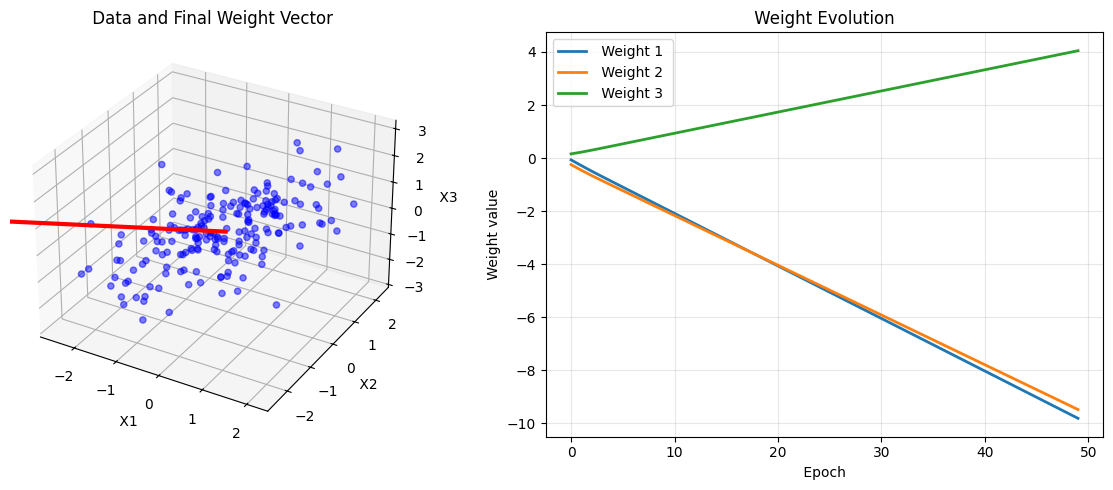

In [9]:
def visualize_hebbian_learning_3d(X , learning_rate =0.01 , epochs=50) :
    """ Visualize weight evolution in 3 D for 3 - input data """
    from mpl_toolkits.mplot3d import Axes3D

    # Create 3 D data if needed
    if X.shape[1] == 2:
        # Add a third dimension
        X_3d = np.column_stack([ X , np.random.randn( X.shape [0]) *
        0.5])
    else :
        X_3d = X

    # Train Hebbian neuron
    hebb = HebbianNeuron( n_inputs =3 , learning_rate = learning_rate )
    hebb.train( X_3d , epochs = epochs , verbose = False )

    # Create 3 D plot
    fig = plt.figure( figsize =(12 , 5) )

    ax1 = fig.add_subplot(1 , 2 , 1 , projection = '3d')
    ax1.scatter( X_3d[: , 0] , X_3d[: , 1] , X_3d[: , 2] , alpha =0.5 , c =
    'blue')
    # Plot final weight vector
    ax1.quiver(0 , 0 , 0 ,
    hebb.weights[0] , hebb.weights[1] , hebb.weights[2] ,
    color = 'red' , linewidth =3 , arrow_length_ratio =0.1)
    
    ax1.set_xlabel( ' X1 ')
    ax1.set_ylabel( ' X2 ')
    ax1.set_zlabel( ' X3 ')
    ax1.set_title( ' Data and Final Weight Vector ')

    ax2 = fig.add_subplot(1 , 2 , 2)
    weight_history = np.array( hebb.weight_history )
    ax2.plot( weight_history[: , 0] , label = ' Weight 1 ' , linewidth =2)
    ax2.plot( weight_history[: , 1] , label = ' Weight 2 ' , linewidth =2)
    ax2.plot( weight_history[: , 2] , label = ' Weight 3 ' , linewidth =2)
    ax2.set_xlabel( ' Epoch ')
    ax2.set_ylabel( ' Weight value ')
    ax2.set_title( ' Weight Evolution ')
    ax2.legend()
    ax2.grid( True , alpha =0.3)

    plt.tight_layout()
    plt.show()

    return hebb
# Generate 3 D correlated data
np.random.seed (42)
X_3d = np.random.multivariate_normal(
mean =[0 , 0 , 0] ,
cov =[[1 , 0.7 , 0.5] ,
[0.7 , 1 , 0.6] ,
[0.5 , 0.6 , 1]] ,
size =200
)
hebb_3d = visualize_hebbian_learning_3d( X_3d , learning_rate =0.01 ,
epochs =50)

### Additional exercises:
1 - Hebbian learning with different activation functions(Tanh)

In [10]:
class HebbianTanh(HebbianNeuron):

    def activation(self, x):
        z = np.dot(x, self.weights) + self.bias
        return np.tanh(z)
np.random.seed(42)
X = np.random.randn(200, 2)

hebb_sigmoid = HebbianNeuron(2, 0.01).train(X, 30)
hebb_tanh = HebbianTanh(2, 0.01).train(X, 30)

print("Sigmoid final weights:", hebb_sigmoid.weights)
print("Tanh final weights:", hebb_tanh.weights)

Epoch 5/30, Weights:[-0.23143719  0.27500897]
Epoch 10/30, Weights:[-0.16804355  0.66259637]
Epoch 15/30, Weights:[-0.10462121  1.05014625]
Epoch 20/30, Weights:[-0.04119886  1.43769611]
Epoch 25/30, Weights:[0.02222349 1.82524598]
Epoch 30/30, Weights:[0.08564584 2.21279585]
Epoch 5/30, Weights:[ 0.12266345 -0.43511902]
Epoch 10/30, Weights:[ 0.18608584 -0.04756948]
Epoch 15/30, Weights:[0.24950819 0.33998039]
Epoch 20/30, Weights:[0.31293053 0.72753026]
Epoch 25/30, Weights:[0.37635288 1.11508012]
Epoch 30/30, Weights:[0.43977523 1.50262999]
Sigmoid final weights: [0.08564584 2.21279585]
Tanh final weights: [0.43977523 1.50262999]


2 - Decorrelation with anti_Hebbian learning using a negative learning rate

In [11]:
hebb_anti = HebbianNeuron(2, learning_rate=-0.01)
hebb_anti.train(X, epochs=30)

print("Anti-Hebbian weights:", hebb_anti.weights)

Epoch 5/30, Weights:[-0.032107   -0.04547454]
Epoch 10/30, Weights:[-0.02136584 -0.04563397]
Epoch 15/30, Weights:[-0.01734897 -0.04525108]
Epoch 20/30, Weights:[-0.0152498 -0.0449171]
Epoch 25/30, Weights:[-0.01395697 -0.04465359]
Epoch 30/30, Weights:[-0.01307891 -0.04444449]
Anti-Hebbian weights: [-0.01307891 -0.04444449]


3 - Competitive learning:
Winner takes all the network 

In [12]:
class CompetitiveHebb:
    def __init__(self, n_neurons, n_inputs, lr=0.01):
        self.neurons = [HebbianNeuron(n_inputs, lr) for _ in range(n_neurons)]

    def train(self, X, epochs=20):
        for _ in range(epochs):
            for x in X:
                activations = [n.activation(x) for n in self.neurons]
                winner = np.argmax(activations)
                y = activations[winner]
                self.neurons[winner].hebbian_update(x, y)
comp = CompetitiveHebb(3, 2, 0.01)
comp.train(X, 30)

for i, neuron in enumerate(comp.neurons):
    print(f"Neuron {i} weights:", neuron.weights)

Neuron 0 weights: [ 0.20406223 -0.02809333]
Neuron 1 weights: [-0.7527624   2.15485265]
Neuron 2 weights: [0.40117163 0.6081871 ]


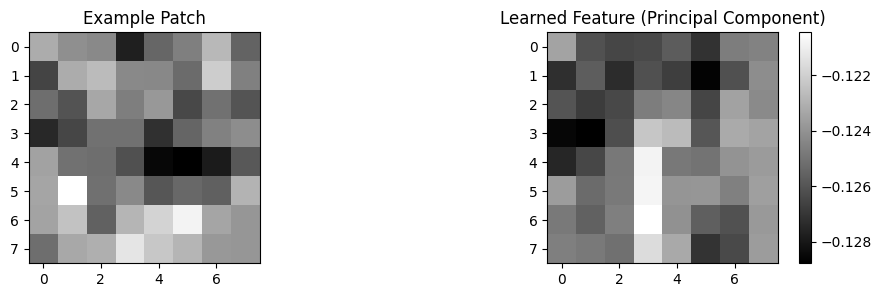

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.image import extract_patches_2d
from skimage import data, color

# Load and preprocess an image
# Using a standard grayscale image (camera man)
img = color.rgb2gray(data.camera()) if data.camera().ndim == 3 else data.camera()
img = (img - np.mean(img)) / np.std(img) # Normalize for better convergence

# Extract Patches
patch_size = (8, 8)
n_patches = 5000
patches = extract_patches_2d(img, patch_size, max_patches=n_patches, random_state=42)

# Flatten patches: (5000, 8, 8) -> (5000, 64)
X = patches.reshape(n_patches, -1)
X -= np.mean(X, axis=0) # Center the data (crucial for PCA)



input_dim = patch_size[0] * patch_size[1]
model = OjaNeuron(input_dim, learning_rate=0.001)
model.train(X, epochs=10)


learned_pattern = model.weights.reshape(patch_size)

plt.figure(figsize=(12, 3))
plt.subplot(1, 2, 1)
plt.title("Example Patch")
plt.imshow(patches[0], cmap='gray')

plt.subplot(1, 2, 2)
plt.title("Learned Feature (Principal Component)")
plt.imshow(learned_pattern, cmap='gray')
plt.colorbar()
plt.show()